In [2]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [3]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [4]:
#ok so we're going to try and compare the current style of fitting (elliptical gaussian) to the idea of taking many slices of gaussians and then drawing a line to connect their peaks to find the orientation
#first, define a new class for the optimizer

class sliced_gauss:
    def __init__(self,wavelength=656E-9,bandwidth=100E-9,grating_angle=28,grating_freq=47):
        self.wavelength = wavelength
        self.bandwidth = bandwidth
        self.grating_angle = grating_angle
        self.grating_freq = grating_freq
        self.normalized_wavelength = wavelength / 656E-9 #normalizing the wavelengths to the ha values
        self.normalized_bandwidth = bandwidth / 656E-9 
        self.maxiter = 5
        self.control_mtx = np.matrix([[0,0],])
        self.current_speckle = None
        self.centers = []
    
    def make_gaussian(self, mu_x, sigma_x):
        def func(grid):
            new_grid = grid.shifted([-mu_x, 0])
            x = new_grid.x / sigma_x
            r2 = x**2 
            return Field(np.exp(-0.5 * r2), grid)
        return func


In [5]:
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(40)
    popt = curve_fit(gauss,x,isolated,p0=[20,2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

160000
(400, 400)
[ 46.34321811 -24.06416566]
1600


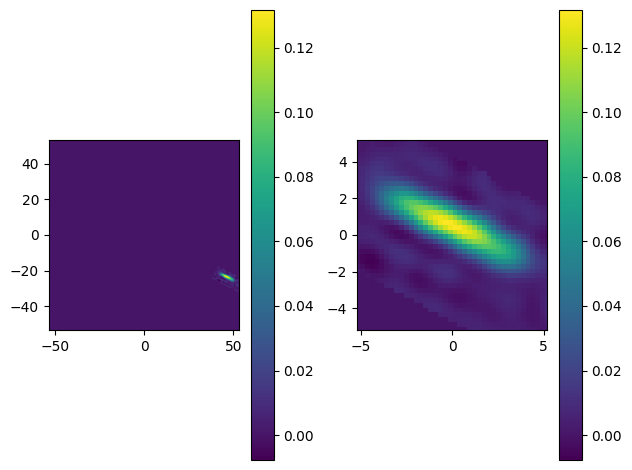

In [6]:
img = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')[0]

img = ADC.filter_image(ADC.crop_image((img)))
speckle_number = 1

img = ADC.find_speckle(img,speckle_number) # you don't need to do this because the cropped frame will exclude the rest of the image
#but for now we keep it because it allows us to isolate each speckle

plt.subplot(1,2,1)
imshow_field(img)
plt.colorbar()

ADC.set_measurement(img)
print(img.size)

extent=40
center_of_intensity = np.array([sum(img*img.grid.x)/sum(img),sum(img*img.grid.y)/sum(img)])
print(img.shaped.shape)
print(center_of_intensity)
img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],extent,extent)
print(img.size)

plt.subplot(1,2,2)
imshow_field(img)
plt.colorbar()
plt.tight_layout()
plt.show()


In [7]:
#ok now we should slice through the whole image, find the means of each distribution, and then plot them on the image to see if it gives us a good idea of the direction we're pointing
print(img.shaped.shape)

shaped = img.shaped
mus = np.zeros(extent)
stds = np.zeros(extent)
fwhms = np.zeros(extent)
resid_sum = np.zeros(extent)



for i in range(extent):
    if speckle_number % 2 != 0:
        sliced = shaped[:,i]
    else: sliced = shaped[i,:]
    s = isolate_gaussian(sliced)
    s /= s.max()
    m, std, fwhm = mu(s)
    mus[i] = m
    stds[i] = std
    fwhms[i] = fwhm
    resid_sum[i] = np.sum(np.abs(gauss(s,m,std) - s))
    


(40, 40)


/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_94309/2102408585.py:4: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


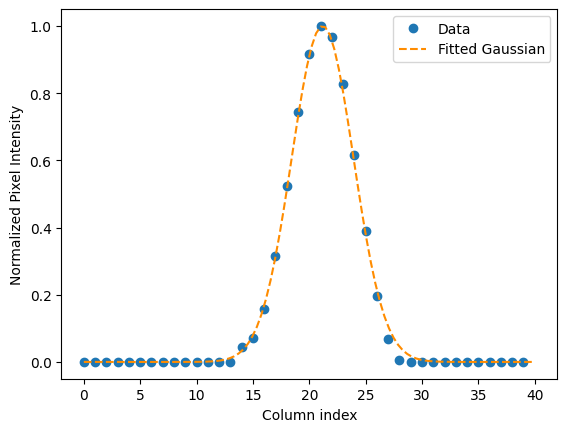

In [24]:
sliced = shaped[:,20]

s = isolate_gaussian(sliced)
s /= s.max()

mean, sd, width = mu(s)

gauss_x = np.linspace(0,40,100)

x = np.arange(40)
plt.figure()
plt.plot(s,'o',label='Data')
plt.plot(gauss_x,gauss(gauss_x,mean,sd),'--',label='Fitted Gaussian',color='darkorange')
plt.xlabel('Column index')
plt.ylabel('Normalized Pixel Intensity')
#plt.plot(x,s - gauss(x,mean,sd),'o',label='Residuals')
# plt.vlines(mean - width/2,0,1,'gray',label='FWHM bounds')
# plt.vlines(mean + width/2,0,1,'gray')
plt.legend()
plt.show()

In [290]:
deriv = np.gradient(mus)
deriv2 = np.gradient(deriv)

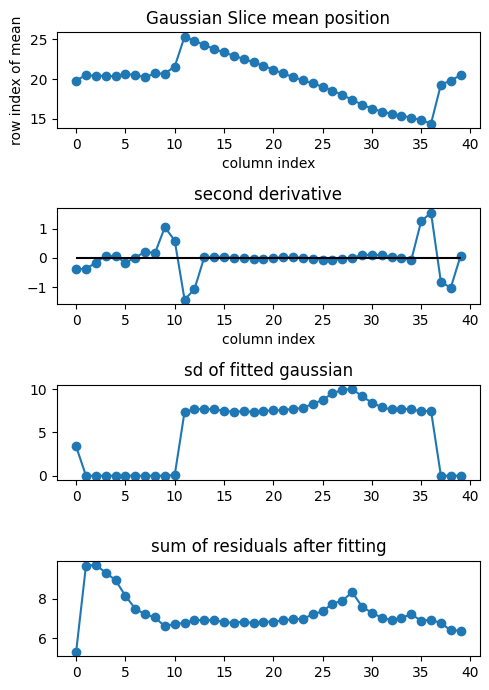

In [297]:
#plot the position of the mean as a function of pixel column
plt.figure(figsize=(5,7))

plt.subplot(4,1,1)
plt.plot(x,mus,'-o')
plt.title('Gaussian Slice mean position')
plt.xlabel('column index')
plt.ylabel('row index of mean')

plt.subplot(4,1,2)
plt.plot(x,deriv2,'-o')
plt.hlines(0,x.min(),x.max(),colors='black')
plt.title('second derivative')
plt.xlabel('column index')

#plot the fwhms
# plt.subplot(4,1,2)
# plt.plot(x,fwhms,'-o')
# plt.title('width of fitted gaussian')
# plt.ylabel('fwhm (pixels)')

#plot the standard deviations
plt.subplot(4,1,3)
plt.plot(x,stds,'-o')
plt.title('sd of fitted gaussian')

#plot the sum of the residuals
plt.subplot(4,1,4)
plt.plot(x,resid_sum,'-o')
plt.title('sum of residuals after fitting')
plt.tight_layout()
plt.show()

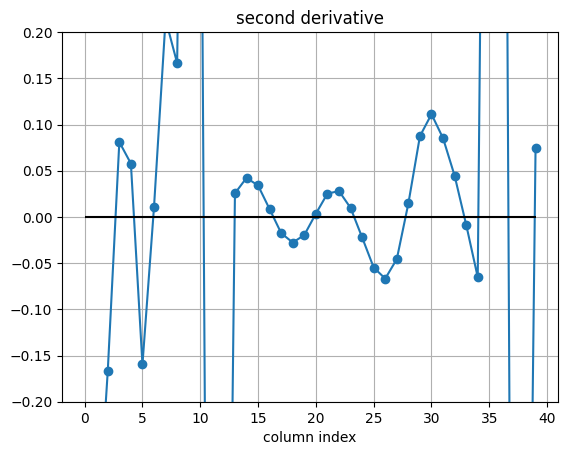

In [292]:
plt.plot(x,deriv2,'-o')
plt.hlines(0,x.min(),x.max(),colors='black')
plt.title('second derivative')
plt.xlabel('column index')
plt.ylim((-0.2,0.2))
plt.grid()


In [293]:
print(deriv2)

nonlin_region = np.squeeze(np.where(np.abs(deriv2) > 0.4))

midpoint = 20
leftbound = nonlin_region[nonlin_region < midpoint][-1]
rightbound = nonlin_region[nonlin_region > midpoint][0]

print(nonlin_region)
print(leftbound)
print(rightbound)

[-0.38649442 -0.36448622 -0.16670038  0.08110587  0.05777213 -0.15967574
  0.01077918  0.21391059  0.16650742  1.04310852  0.5911485  -1.41671283
 -1.06402879  0.02557772  0.04225213  0.03401184  0.00840134 -0.01755537
 -0.0277311  -0.01960114  0.00352492  0.02526189  0.02796866  0.00977595
 -0.02217376 -0.05477958 -0.06677743 -0.04563032  0.0145817   0.08740427
  0.11121359  0.0851808   0.04460436 -0.00844753 -0.06525251  1.25071417
  1.53288828 -0.81309554 -1.01232386  0.07467961]
[ 9 10 11 12 35 36 37 38]
12
35


23
23
slope: -0.45
corresponding angle: -0.43 (rad) or -24.36°


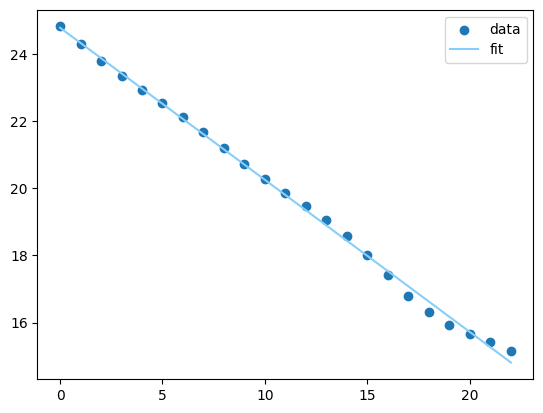

In [294]:
#crop out the linear region of the means plot, fit a line, and find the slope & angle of the distribution

linear_region = mus[leftbound:rightbound]
lin_x = np.arange(len(linear_region))

print(len(linear_region))
print(len(lin_x))


m , b = np.polyfit(lin_x,linear_region,deg=1)
angle = np.arctan(m)
print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')
plt.scatter(lin_x,linear_region,label='data')
plt.plot(lin_x, m * lin_x + b,label='fit',color='LightSkyBlue')
plt.legend()
plt.show()
